# ACME Inc. — Performance & Talent Insights

This notebook answers ACME's seven workforce questions from the **Gold layer** of the
data lake. Every number below is computed live from Gold; nothing is typed in by hand.

| # | Business question | Gold table |
|---|---|---|
| 1 | Performance ratings and review history per employee | `employee_performance_history` |
| 2 | Employees with critical skill gaps | `employee_skill_gaps` |
| 3 | High-potential employees ready for promotion | `promotion_pipeline` |
| 4 | Training and development completed per employee | `employee_course_progress`, `employee_learning_summary` |
| 5 | Employees at risk of attrition, based on performance trends | `attrition_risk` |
| 6 | Performance vs. team and project outcomes | `team_performance_outcomes` |
| 7 | Distribution of skills across the organization | `skill_distribution` |

**How the data got here:** PostgreSQL (HR system) and S3 (learning platform) → **Bronze** (raw, immutable)
→ **Silver** (validated, cleaned, bad records quarantined) → **Gold** (one table per question).
Section 0 shows the pipeline health checks behind these numbers.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.dataset as ds
import pyarrow.fs as pafs

# Same environment variables as the pipeline (local: LocalStack, cloud: AWS S3).
IS_LOCAL = os.environ.get("IS_LOCAL", "true").lower() == "true"
BUCKET = os.environ.get("DATALAKE_BUCKET") or f"coding-workshop-datalake-{os.environ.get('PARTICIPANT_ID', 'abcd1234')}"
ENDPOINT = os.environ.get("AWS_ENDPOINT_URL_S3") or ("http://s3.localhost.localstack.cloud:4566" if IS_LOCAL else None)
REGION = os.environ.get("AWS_REGION", "us-east-1")

fs_args = {"region": REGION}
if ENDPOINT:
    fs_args.update(endpoint_override=ENDPOINT, scheme="http" if ENDPOINT.startswith("http://") else "https")
fs = pafs.S3FileSystem(**fs_args)


def read(prefix: str) -> pd.DataFrame:
    """Read a Parquet dataset from the data lake."""
    return ds.dataset(f"{BUCKET}/{prefix}", filesystem=fs, format="parquet", partitioning="hive").to_table().to_pandas()


def gold(table: str) -> pd.DataFrame:
    return read(f"gold/{table}")


def read_json(key: str) -> dict:
    with fs.open_input_stream(f"{BUCKET}/{key}") as f:
        return json.loads(f.read())


print(f"Data lake: s3://{BUCKET}  ({'local' if IS_LOCAL else 'cloud'})")

Data lake: s3://coding-workshop-datalake-abcd1234  (local)


In [2]:
# Chart style: one shared look for every figure.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # sequential blue
CRITICAL = "#d03b3b"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})
from matplotlib.colors import LinearSegmentedColormap
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)


def label_bars(ax, fmt="{:,.0f}", horizontal=False):
    """Direct value labels in ink color (never the series color)."""
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if horizontal:
            ax.annotate(fmt.format(v), (v, p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=9, color=INK2)
        else:
            ax.annotate(fmt.format(v), (p.get_x() + p.get_width() / 2, v), xytext=(0, 3), textcoords="offset points",
                        ha="center", fontsize=9, color=INK2)

## 0. Pipeline health — can these numbers be trusted?

Before answering anything: did every record arrive, and what was rejected? The pipeline writes a
data quality report and per-step lineage on every run (`_meta/`).

In [3]:
report = read_json("_meta/dq_reports/latest/report.json")
rows = []
for entity, s in report["entities"].items():
    if "bronze_rows" in s:
        rows.append({"entity": entity, "bronze (raw)": s["bronze_rows"], "silver (clean)": s["silver_rows"],
                     "quarantined": s["quarantined_rows"], "duplicates dropped": s["duplicates_dropped"],
                     "reconciles": "yes" if report["reconciliation"][entity] else "NO"})
health = pd.DataFrame(rows).set_index("entity")
print(f"Run {report['run_id']} - every entity reconciles: bronze = silver + quarantined + duplicates")
health

Run 20261015T023717Z-833f98 - every entity reconciles: bronze = silver + quarantined + duplicates


,bronze (raw),silver (clean),quarantined,duplicates dropped,reconciles
entity,,,,,
teams,100,100,0,0,yes
competencies,40,40,0,0,yes
employees,2000,2000,0,0,yes
projects,33,33,0,0,yes
performance_reviews,4000,4000,0,0,yes
competency_assessments,4000,4000,0,0,yes
talent_review,2000,2000,0,0,yes
learning_events,29868,29536,182,150,yes


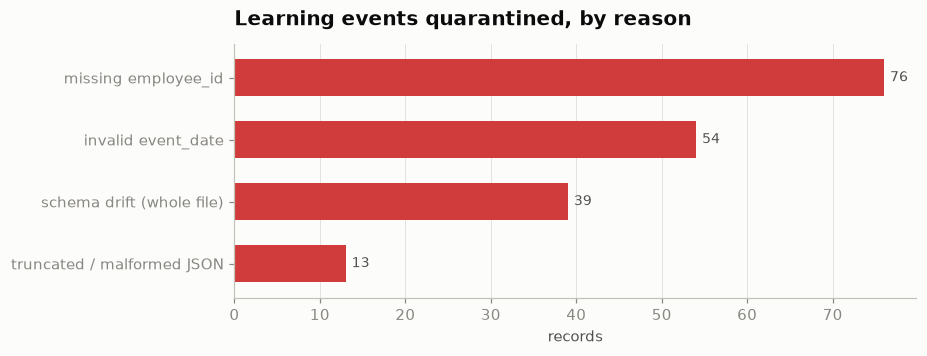

Quarantined file(s): ['s3://coding-workshop-datalake-abcd1234/landing/learning_activity/year=2024/month=09/day=03/events-000.jsonl']


In [4]:
READABLE = {"employee_id": "missing employee_id", "event_date": "invalid event_date",
            "file quarantined for schema drift": "schema drift (whole file)", "malformed JSON": "truncated / malformed JSON"}
reasons = pd.Series(report["entities"]["learning_events"]["rejection_reasons"]).rename(lambda r: READABLE.get(r.split(":")[0], r.split(":")[0]))
reasons = reasons.groupby(level=0).sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
reasons.plot.barh(ax=ax, color=CRITICAL, width=0.6)
label_bars(ax, horizontal=True)
ax.set_title("Learning events quarantined, by reason")
ax.set_xlabel("records"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
plt.show()
print("Quarantined file(s):", report["entities"]["learning_events"]["quarantined_files"])

**Reading:** the learning-platform feed contained truncated JSON lines, records without an employee,
unparseable dates, duplicate events and one file whose schema had drifted (`text` renamed to `notes`).
None of these reach the analysis below: they are held in `quarantine/` with the reason for each.
Every HR table from PostgreSQL passed all checks.

## 1. Performance ratings and review history

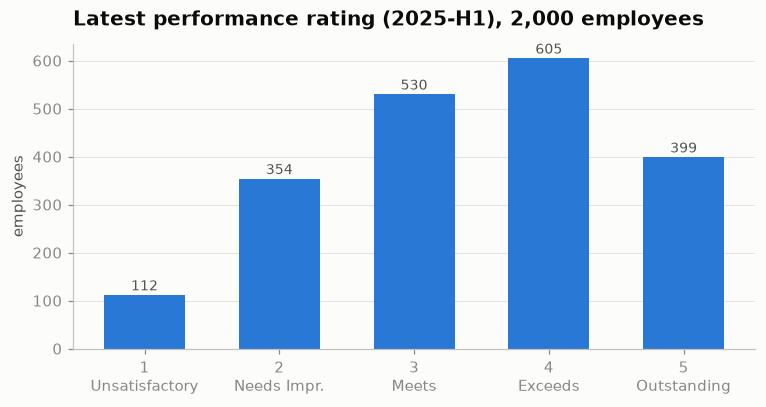

Average latest rating: 3.41  |  rated 4-5: 50%  |  rated 1-2: 23%


In [5]:
history = gold("employee_performance_history")
latest = history[history["is_latest_review"]]
dist = latest["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([f"{r}\n{l}" for r, l in zip(dist.index, ["Unsatisfactory", "Needs Impr.", "Meets", "Exceeds", "Outstanding"])],
       dist.values, color=BLUE, width=0.6)
label_bars(ax)
ax.set_title(f"Latest performance rating (2025-H1), {len(latest):,} employees")
ax.set_ylabel("employees"); ax.grid(axis="x", visible=False)
plt.show()
print(f"Average latest rating: {latest['rating'].mean():.2f}  |  rated 4-5: {(latest['rating'] >= 4).mean():.0%}  |  rated 1-2: {(latest['rating'] <= 2).mean():.0%}")

In [6]:
trend = latest["rating_change"].apply(lambda d: "Declined" if d < 0 else ("Improved" if d > 0 else "No change")).value_counts()
print("Change since previous review (2024-H2 -> 2025-H1):", trend.to_dict())

# Review history for any employee - change the id to look someone up.
EMPLOYEE_ID = int(latest.sort_values(["rating_change", "employee_id"]).iloc[0]["employee_id"])
history[history["employee_id"] == EMPLOYEE_ID][["full_name", "department", "review_period", "rating", "rating_label", "rating_change", "manager_comment"]]

Change since previous review (2024-H2 -> 2025-H1): {'Improved': 898, 'No change': 872, 'Declined': 230}


,full_name,department,review_period,rating,rating_label,rating_change,manager_comment
14,Mike Gamble,Operations,2024-H2,3,Meets Expectations,NaN,Delivered on commitments with no major concerns.
15,Mike Gamble,Operations,2025-H1,1,Unsatisfactory,-2.0,Engagement and output have both trended down.


**Answer:** every employee has two reviews (2024-H2 and 2025-H1). Most of the workforce sits at
*Meets* or *Exceeds*, and more employees improved than declined. The full history is in
`employee_performance_history`, one row per employee per period; the cell above shows how to look up any employee.

## 2. Critical skill gaps

A **gap** is `required level − proficiency level` for an assessed competency.
A gap of **2 or more levels** is treated as **critical** (assumption, documented in `docs/limitations.md`).

317 employees have at least one critical gap (325 of 4,000 assessments).


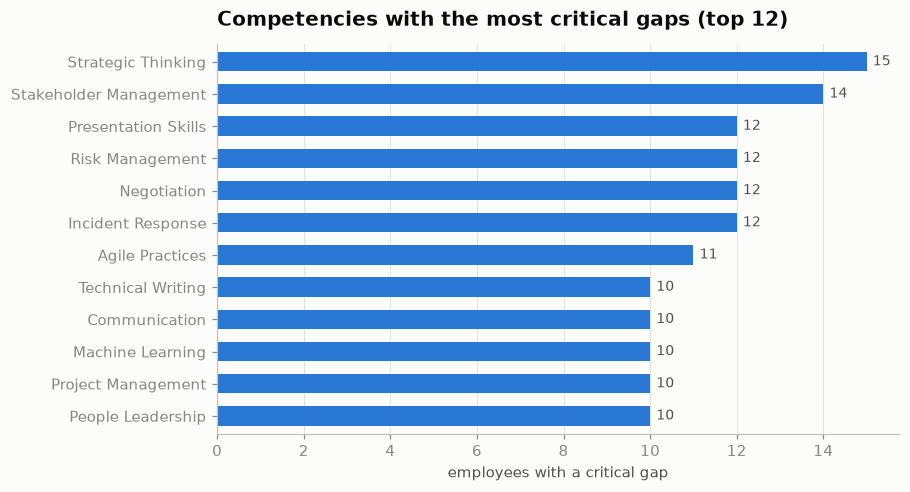

In [7]:
gaps = gold("employee_skill_gaps")
critical = gaps[gaps["is_critical_gap"]]
print(f"{critical['employee_id'].nunique():,} employees have at least one critical gap "
      f"({len(critical):,} of {len(gaps):,} assessments).")

by_comp = critical.groupby("competency_name").size().sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
by_comp.plot.barh(ax=ax, color=BLUE, width=0.6)
label_bars(ax, horizontal=True)
ax.set_title("Competencies with the most critical gaps (top 12)")
ax.set_xlabel("employees with a critical gap"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
plt.show()

In [8]:
# Who to prioritise: employees with critical gaps, largest gaps first.
critical.sort_values(["gap", "employee_id"], ascending=[False, True])[
    ["employee_id", "full_name", "department", "job_level", "competency_name", "competency_category", "proficiency_level", "required_level", "gap"]
].head(15)

,employee_id,full_name,department,job_level,competency_name,competency_category,proficiency_level,required_level,gap
3240,2,Kristie Heath,Sales,Director,Strategic Thinking,Leadership,2,4,2
1132,5,Linda Murray,Sales,IC1,Machine Learning,Technical,1,3,2
2065,11,Natalie Wallace,Sales,Director,Coaching & Mentoring,Leadership,1,3,2
2806,19,Kaylee Reid,Design,Senior Manager,People Leadership,Leadership,1,3,2
1419,31,Douglas Salinas,Design,Director,Data Privacy,Domain,2,4,2
2066,33,Madison Kirby,Design,Director,Security Fundamentals,Technical,1,3,2
476,38,David Gonzalez,Design,Senior Manager,Data Modeling,Technical,1,3,2
2931,40,Lindsey Harris,Design,IC1,People Leadership,Leadership,2,4,2
1198,49,Brandon Weiss,Sales,Senior Manager,Machine Learning,Technical,1,3,2
2217,52,Kelly Smith,Sales,Senior IC,Agile Practices,Domain,2,4,2


**Answer:** critical gaps are spread across many competencies rather than concentrated in one.
*Domain* skills (stakeholder management, negotiation, risk management, presentation) account for the
largest share. The table lists the people and skills to target with development plans.

## 3. High-potential employees ready for promotion

Uses the industry-standard **9-box grid**: latest performance (Low 1–2, Moderate 3, High 4–5) against
potential from the talent review. A **promotion candidate** is *High potential* **and** *Ready Now*
**and** rated 4 or higher in the latest review.

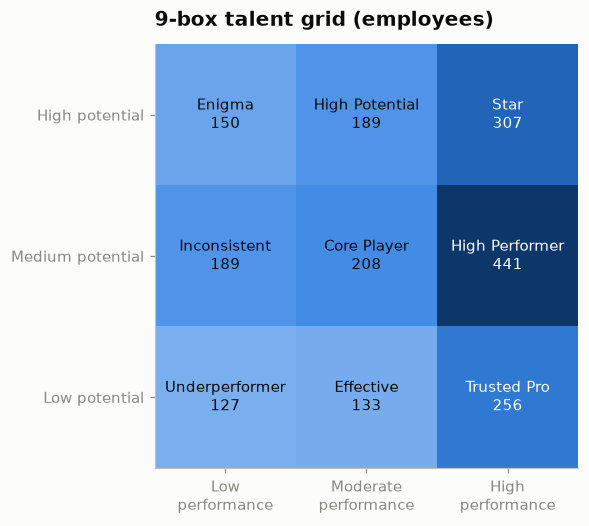

In [9]:
pipeline = gold("promotion_pipeline")
grid = pd.crosstab(pipeline["potential_rating"], pipeline["performance_band"]).reindex(
    index=["High", "Medium", "Low"], columns=["Low", "Moderate", "High"])
labels = {("High", "Low"): "Enigma", ("High", "Moderate"): "High Potential", ("High", "High"): "Star",
          ("Medium", "Low"): "Inconsistent", ("Medium", "Moderate"): "Core Player", ("Medium", "High"): "High Performer",
          ("Low", "Low"): "Underperformer", ("Low", "Moderate"): "Effective", ("Low", "High"): "Trusted Pro"}

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.imshow(grid.values, cmap=SEQ_CMAP, vmin=0)
for i, pot in enumerate(grid.index):
    for j, perf in enumerate(grid.columns):
        v = grid.loc[pot, perf]
        color = "white" if v > grid.values.max() * 0.55 else INK
        ax.text(j, i, f"{labels[(pot, perf)]}\n{v:,}", ha="center", va="center", color=color, fontsize=10)
ax.set_xticks(range(3), [f"{c}\nperformance" for c in grid.columns]); ax.set_yticks(range(3), [f"{p} potential" for p in grid.index])
ax.grid(False); ax.set_title("9-box talent grid (employees)")
plt.show()

166 promotion candidates (357 are High potential + Ready Now; rating >= 4 narrows it to 166).
34 candidates still have a critical skill gap to close before promotion.


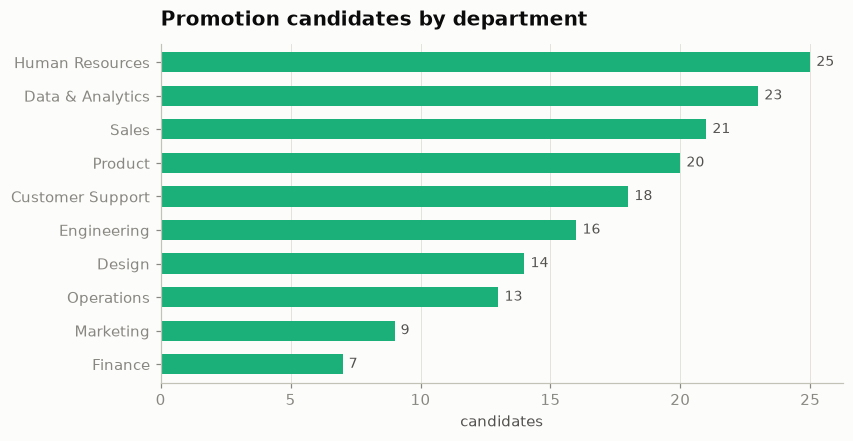

,employee_id,full_name,department,job_level,latest_rating,nine_box,critical_gap_count,certifications
643,932,Donald Nichols,Product,IC2,5,Star,1,5
996,1527,Sarah Rivera,Sales,Senior Manager,5,Star,0,3
1032,1833,Linda Crawford,Sales,IC2,5,Star,1,3
1214,1484,Melissa Anderson,Design,IC2,5,Star,0,3
1367,701,Yolanda Foley,Marketing,IC2,5,Star,0,3
406,988,Brian Moore,Sales,IC1,5,Star,1,2
700,1346,Thomas Walker,Human Resources,IC2,5,Star,0,2
824,145,Lisa Johnson,Product,Manager,5,Star,0,2
1009,1634,Christine Davis,Design,Director,5,Star,0,2
1082,297,Nicole Boyd,Product,Manager,5,Star,0,2


In [10]:
candidates = pipeline[pipeline["is_promotion_candidate"]]
print(f"{len(candidates):,} promotion candidates "
      f"({(pipeline['is_high_potential'] & pipeline['is_ready_now']).sum():,} are High potential + Ready Now; "
      f"rating >= 4 narrows it to {len(candidates):,}).")
print(f"{(candidates['critical_gap_count'] > 0).sum()} candidates still have a critical skill gap to close before promotion.")

by_dept = candidates["department"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
by_dept.plot.barh(ax=ax, color=AQUA, width=0.6)
label_bars(ax, horizontal=True)
ax.set_title("Promotion candidates by department"); ax.set_xlabel("candidates"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
plt.show()
candidates.sort_values(["latest_rating", "certifications"], ascending=False)[
    ["employee_id", "full_name", "department", "job_level", "latest_rating", "nine_box", "critical_gap_count", "certifications"]
].head(15)

**Answer:** the shortlist is in `promotion_pipeline` (`is_promotion_candidate = true`), sorted above.
Candidates who still carry a critical skill gap should get a targeted development plan alongside promotion.

## 4. Training and development completed

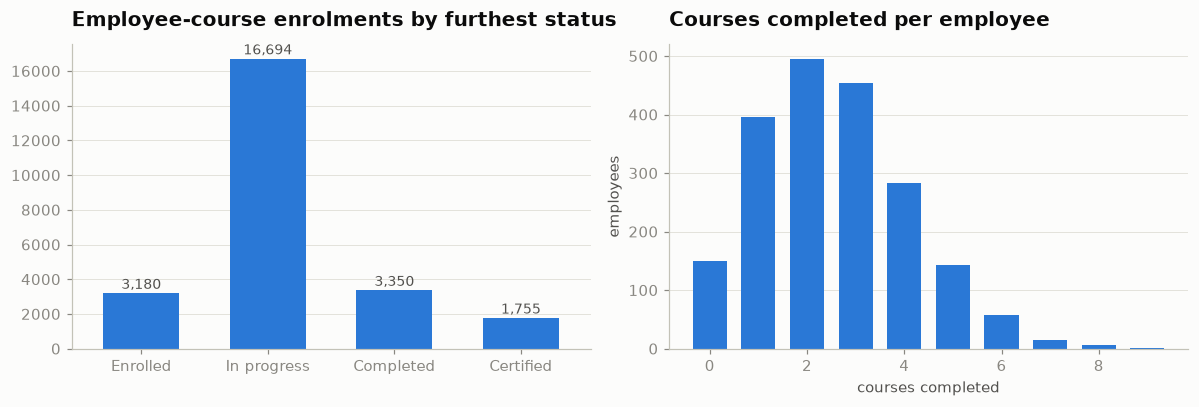

Median courses completed: 2  |  certifications earned: 1,755  |  employees with no completed course: 149


In [11]:
progress = gold("employee_course_progress")
summary = gold("employee_learning_summary")
status = progress["status"].value_counts().reindex(["Enrolled", "In progress", "Completed", "Certified"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
status.plot.bar(ax=axes[0], color=BLUE, width=0.6, rot=0)
label_bars(axes[0]); axes[0].set_title("Employee-course enrolments by furthest status"); axes[0].set_xlabel(""); axes[0].grid(axis="x", visible=False)
counts = summary["courses_completed"].value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color=BLUE, width=0.7)
axes[1].set_title("Courses completed per employee"); axes[1].set_xlabel("courses completed"); axes[1].set_ylabel("employees"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Median courses completed: {summary['courses_completed'].median():.0f}  |  certifications earned: {summary['certifications'].sum():,}  |  "
      f"employees with no completed course: {(summary['courses_completed'] == 0).sum():,}")

In [12]:
# Completed training for any employee (change the id).
EMPLOYEE_ID = int(summary.sort_values("courses_completed", ascending=False).iloc[0]["employee_id"])
progress[(progress["employee_id"] == EMPLOYEE_ID) & progress["is_completed"]][
    ["full_name", "course_name", "competency_name", "status", "completed_on", "certified_on", "best_quiz_score"]
]

,full_name,course_name,competency_name,status,completed_on,certified_on,best_quiz_score
217,Bryan Ware,Time Management for Professionals,Time Management,Completed,2024-12-09,None,NaN
436,Bryan Ware,Test Automation Bootcamp,Test Automation,Certified,2025-12-18,2026-08-27,20.0
583,Bryan Ware,Resolving Team Conflict,Conflict Resolution,Completed,2024-05-20,None,NaN
609,Bryan Ware,Customer Empathy Workshop,Customer Empathy,Certified,None,2024-07-18,NaN
1176,Bryan Ware,New Hire Onboarding Enablement,Onboarding & Enablement,Completed,2024-12-13,None,NaN
1226,Bryan Ware,Project Management Fundamentals,Project Management,Completed,2023-10-17,None,NaN
1707,Bryan Ware,API Design Best Practices,API Design,Certified,None,2023-10-17,NaN
2948,Bryan Ware,Dimensional Data Modeling,Data Modeling,Completed,2025-08-29,None,NaN
2958,Bryan Ware,Effective Decision Making,Decision Making,Completed,2025-09-05,None,NaN


**Answer:** `employee_course_progress` has one row per employee per course with its milestones;
`employee_learning_summary` has one row per employee, including the list of completed courses.
Each course is linked to the competency it develops, so training can be matched against the skill gaps in section 2.

## 5. Attrition risk based on performance trends

Two views side by side:
* **HR risk:** the manager-assessed flag from the talent review.
* **Derived risk:** computed from data signals. Rating declined (+2), latest rating ≤ 2 (+2), negative manager
  comment (+1), no learning activity in the last 180 days (+1). A score of 3 or more is High.

With only two review periods, a "trend" is one period-over-period change (see limitations).

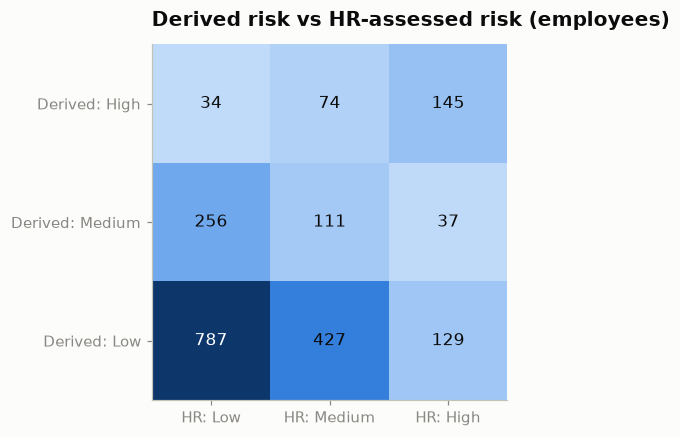

At risk by either view: 419  |  High in BOTH views: 145  |  High-potential employees at risk: 136


In [13]:
risk = gold("attrition_risk")
xtab = pd.crosstab(risk["derived_risk_level"], risk["hr_attrition_risk"]).reindex(index=["High", "Medium", "Low"], columns=["Low", "Medium", "High"])
fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.imshow(xtab.values, cmap=SEQ_CMAP, vmin=0)
for i in range(3):
    for j in range(3):
        v = xtab.values[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > xtab.values.max() * 0.55 else INK, fontsize=11)
ax.set_xticks(range(3), [f"HR: {c}" for c in xtab.columns]); ax.set_yticks(range(3), [f"Derived: {r}" for r in xtab.index])
ax.grid(False); ax.set_title("Derived risk vs HR-assessed risk (employees)")
plt.show()
both = risk[(risk["derived_risk_level"] == "High") & (risk["hr_attrition_risk"] == "High")]
print(f"At risk by either view: {risk['is_at_risk'].sum():,}  |  High in BOTH views: {len(both):,}  |  "
      f"High-potential employees at risk: {(risk['is_at_risk'] & (risk['potential_rating'] == 'High')).sum():,}")

In [14]:
# Highest priority: flagged by both views, highest derived score first.
both.sort_values(["derived_risk_score", "employee_id"], ascending=[False, True])[
    ["employee_id", "full_name", "department", "previous_rating", "latest_rating", "rating_trend",
     "learning_events_last_180d", "derived_risk_score", "latest_manager_comment"]
].head(15)

,employee_id,full_name,department,previous_rating,latest_rating,rating_trend,learning_events_last_180d,derived_risk_score,latest_manager_comment
541,111,Brian Brock,Finance,2,1,Declining,0,6,Engagement and output have both trended down.
302,243,Robert Brady,Customer Support,3,2,Declining,0,6,Struggled to meet deadlines; follow-up plan re...
1567,371,Anne Long,Operations,4,2,Declining,0,6,Engagement and output have both trended down.
1853,702,Crystal Logan,Marketing,3,1,Declining,0,6,Struggled to meet deadlines; follow-up plan re...
1183,1147,David Mcclure,Human Resources,2,1,Declining,0,6,Engagement and output have both trended down.
438,1225,Amy Tucker,Marketing,2,1,Declining,0,6,Engagement and output have both trended down.
448,1299,Joseph Ford,Design,2,1,Declining,0,6,Struggled to meet deadlines; follow-up plan re...
1709,1550,Rodney Wilkerson,Customer Support,3,2,Declining,0,6,Missed several key deliverables this cycle; ne...
1772,8,Sherry Coleman,Sales,3,2,Declining,3,5,Missed several key deliverables this cycle; ne...
1527,45,Donna Green,Sales,3,2,Declining,2,5,Missed several key deliverables this cycle; ne...


**Answer:** employees flagged **High by both views** are the strongest retention priority; the list is above.
Where the views disagree, the data signals are worth discussing with the manager. HR may know something
the data does not, or the data may show a decline that has not been escalated yet.

## 6. Performance vs. team and project outcomes

Projects belong to teams, not individuals, so this is a **team-level** comparison: the average latest rating
of each team's members against the outcome of that team's projects. Only **27 of 100 teams** have projects
(33 projects in total), so treat the result as indicative.

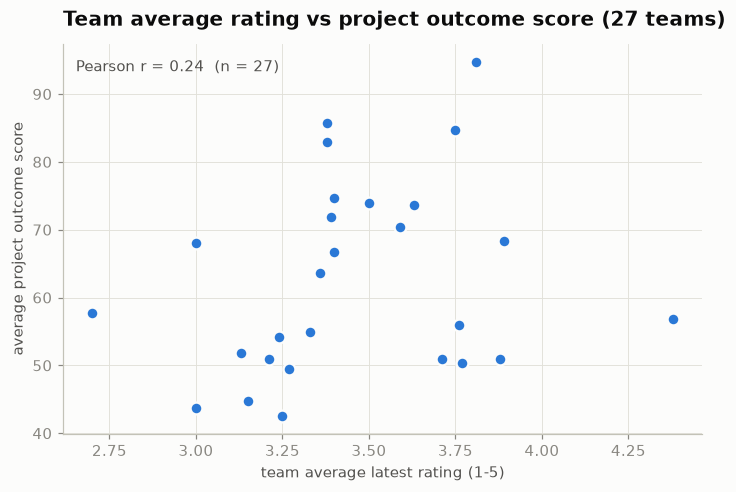

Correlation of team rating with project outcome score: r = 0.24; with on-time delivery rate: r = 0.54


In [15]:
teams = gold("team_performance_outcomes")
with_projects = teams[teams["has_projects"]]
r_score = with_projects["avg_latest_rating"].corr(with_projects["avg_outcome_score"])
r_ontime = with_projects["avg_latest_rating"].corr(with_projects["on_time_rate_pct"])

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(with_projects["avg_latest_rating"], with_projects["avg_outcome_score"], s=60, color=BLUE,
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
ax.set_title("Team average rating vs project outcome score (27 teams)")
ax.set_xlabel("team average latest rating (1-5)"); ax.set_ylabel("average project outcome score")
ax.text(0.02, 0.96, f"Pearson r = {r_score:.2f}  (n = {len(with_projects)})", transform=ax.transAxes, va="top", color=INK2)
plt.show()
print(f"Correlation of team rating with project outcome score: r = {r_score:.2f}; with on-time delivery rate: r = {r_ontime:.2f}")

**Answer:** higher-rated teams tend to deliver better project outcomes, and the link is clearer for
**on-time delivery** than for the outcome score. With 27 teams this is a correlation, not proof that
performance causes outcomes. More projects per team, or employee-level project assignments, would be needed
to confirm it.

## 7. Distribution of skills across the organization

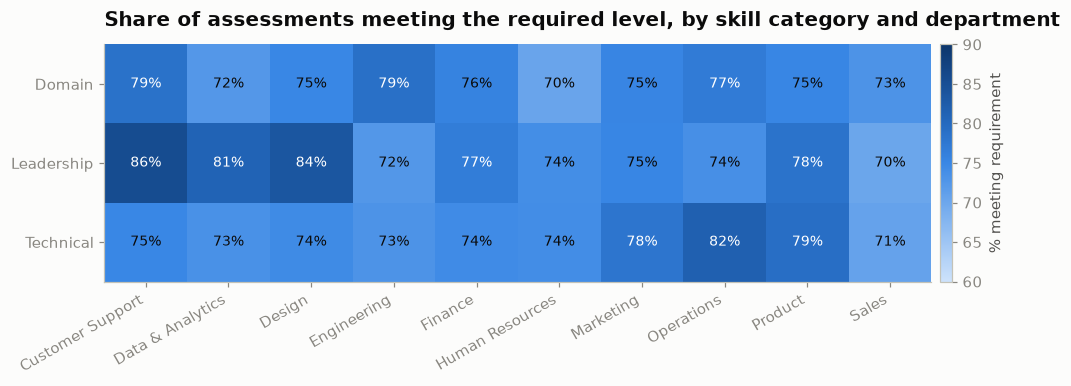

In [16]:
skills = gold("skill_distribution")
coverage = skills.assign(met=skills["pct_meeting_requirement"] * skills["assessments"] / 100)
pivot = (coverage.groupby(["competency_category", "department"])[["met", "assessments"]].sum()
         .assign(pct=lambda d: d["met"] / d["assessments"] * 100)["pct"].unstack())

fig, ax = plt.subplots(figsize=(10, 2.8))
im = ax.imshow(pivot.values, cmap=SEQ_CMAP, aspect="auto", vmin=60, vmax=90)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 76 else INK)
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=30, ha="right"); ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.grid(False); ax.set_title("Share of assessments meeting the required level, by skill category and department")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="% meeting requirement")
plt.show()

In [17]:
by_comp = coverage.groupby(["competency_name", "competency_category"])[["met", "assessments"]].sum()
by_comp["pct_meeting_requirement"] = (by_comp["met"] / by_comp["assessments"] * 100).round(1)
levels = skills.groupby("competency_name")[[f"level_{n}_count" for n in range(1, 6)]].sum()
table = by_comp.drop(columns="met").join(levels).sort_values("pct_meeting_requirement")
print("Weakest and strongest competencies org-wide:")
pd.concat([table.head(5), table.tail(5)])

Weakest and strongest competencies org-wide:


,,assessments,pct_meeting_requirement,level_1_count,level_2_count,level_3_count,level_4_count,level_5_count
competency_name,competency_category,,,,,,,
Stakeholder Management,Domain,92,65.2,20,23,27,16,6
Customer Empathy,Domain,88,68.2,13,18,24,20,13
Presentation Skills,Domain,105,69.5,17,23,20,26,19
Incident Response,Technical,105,69.5,17,21,25,27,15
Negotiation,Domain,103,69.9,13,35,27,16,12
Localization,Domain,109,80.7,15,15,21,42,16
Onboarding & Enablement,Domain,126,81.0,14,26,37,33,16
Decision Making,Leadership,109,81.7,10,22,36,27,14
Data Privacy,Domain,100,82.0,10,16,35,24,15


**Answer:** skill coverage is broadly even across departments, between roughly 70% and 80% of assessments meeting the
required level. The weakest competencies org-wide are customer- and stakeholder-facing *Domain* skills, which
lines up with the critical gaps in section 2. `skill_distribution` holds the full proficiency spread
(levels 1–5) for every competency and department.

## Summary

| Question | Finding (live figures above) |
|---|---|
| Ratings & history | Two reviews per employee; most at *Meets* / *Exceeds*; more improved than declined |
| Critical skill gaps | Spread across competencies; Domain skills dominate |
| Ready for promotion | Shortlist = High potential + Ready Now + rating ≥ 4 (9-box *Stars*) |
| Training completed | Per-employee, per-course milestones; linked to competencies |
| Attrition risk | Two views; *High in both* = top retention priority |
| Performance vs outcomes | Positive team-level link, stronger for on-time delivery; small sample |
| Skill distribution | 70–80% coverage everywhere; stakeholder/customer skills weakest |

Assumptions and limits (critical-gap threshold, risk weights, the course→competency mapping, two review periods,
27 teams with projects) are listed in `docs/limitations.md`.